# Explicit execution state for long-running skills

### Chapter 3's harness, plus one thing: a state it maintains instead of a transcript it replays

Chapter 3 built the harness side of a skill, one step at a time:

> parse the artifacts into typed, hashed, versioned records → route a task to a
> skill and measure what a vague description costs → detect a boundary collision
> between two skills → compile the runtime surface for one task → measure it
> against injecting everything → test the skill as a unit → version it and show
> what a change moves.

All of that decides **which rules** the model reads. It rests on one assumption
that chapter 3 never had to question: a tool (section 5) hands the writer a
**clean, current list of facts**. Four merged changes, `breaking=True`, done.

Real work does not arrive that way. It arrives as a stream over hours. A change is
merged and later reverted. A number is re-measured. A timestamp is corrected.
Someone in chat speculates about the cause, and a support note names a customer.
The deliverables are due partway through. Somebody has to work out what is
*still true* at the moment of writing, and the only question is who does it, and
when.

This chapter keeps chapter 3's harness exactly as it is and changes one thing,
what the harness carries between steps:

| | Chapter 3 harness, run over a stream | Chapter 3 harness **+ SKILL.state** |
|---|---|---|
| between steps | an append-only transcript of events and responses | an explicit state Σ, validated on every step |
| who resolves reverts and corrections | the writer, at write time, from text | a tracker, on the step the event arrives |
| what the writer is handed | the log | Σ: current facts only |
| writer call | chapter 3's, unchanged | chapter 3's, unchanged |

Because the writer call is identical, every difference in the results comes from
the input the writer was handed.

**What "beneficial" has to mean here.** The results are shown in four places,
followed by a scorecard:

1. **Cost** (§5): prompt size per step, and cumulative tokens over the shift.
2. **What the writer is handed** (§6): which traps are still in its input, and
   which required facts are present. This is measured before any writer runs.
3. **The deliverables** (§7): graded against every planted trap.
4. **Tests the harness can now run** (§8): the extension of chapter 3's sections 8
   and 9 to facts. These are a provenance test on the output, a fact only the
   harness can derive, and a state digest in the trace.

A **control** runs alongside: a sliding-window transcript pinned to the state
harness's prompt budget. If the window matches the state harness, the benefit was
only a shorter prompt. If it doesn't, the benefit comes from structure.

**Where the architecture comes from.** SKILL.state is from Badhe, Tiwari & Chung
(2026), *SKILL.state: Scalable Long-Horizon Agent Skills*, arXiv:2608.26263. At
each step the model receives only the procedure *P*, the current state *Σ_t* and
the latest observation *O_t*. The runtime validates the proposed state patch
deterministically, merges it, and discards the reasoning. The code here uses
[`skill_state`](https://github.com/Nicolepcx/skill_state), an **independent
reference implementation** of that runtime written for this book. It is not the
authors' code.

**What runs here.** All of it runs against real models through OpenRouter. The
trackers make a few hundred small-model calls, most of them in the transcript
harness. The writers make a dozen or so. Section 11 prices the whole pass.
`HORIZONS` and `SEEDS` in section 4 set the size of the run.

In [ ]:
%pip install -q instructor

import importlib, shutil, subprocess, sys

SKILL_STATE_REPO = "https://github.com/Nicolepcx/skill_state"
try:
    import skill_state
except ModuleNotFoundError:
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{SKILL_STATE_REPO}"],
                       capture_output=True, text=True)
    if r.returncode != 0:                     # repo without pyproject.toml: use a clone
        shutil.rmtree("/tmp/skill_state_src", ignore_errors=True)
        subprocess.run(["git", "clone", "-q", "--depth", "1", SKILL_STATE_REPO,
                        "/tmp/skill_state_src"], check=True)
        sys.path.insert(0, "/tmp/skill_state_src")
    importlib.invalidate_caches()
    import skill_state
print("skill_state loaded from", skill_state.__file__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 269.4/269.4 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.2/353.2 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 9.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
skill_state loaded from /tmp/skill_state_src/skill_state/__init__.py


## 0. Setup: chapter 3's artifacts and harness, unchanged

These are the same five artifacts from the same shared folder, and the same model
setup. The third code cell below is chapter 3's harness code, **copied verbatim**
from that notebook: the parser (§1), the router (§3), the boundary check (§4),
the compiler (§6), the "everything" baseline (§7) and the release-notes schema
(§7). Nothing in it is modified here. This chapter only adds what sits around it.

In [ ]:
try:
    import gdown
except ModuleNotFoundError:
    %pip install -q gdown
    import gdown

import hashlib, inspect, json, os, re, shutil, textwrap, time
from dataclasses import dataclass, field
from functools import lru_cache
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import yaml

DRIVE_FOLDER_URL = (
    "https://drive.google.com/drive/folders/"
    "1hPCzmDY08tKq5o8vcykap9aFdiQ7UA_4?usp=sharing"
)

WORK = Path("ch03_skill_demo").resolve()

# gdown preserves the Google Drive folder name.
SRC = WORK / "artifacts"

shutil.rmtree(WORK, ignore_errors=True)
WORK.mkdir(parents=True)

kwargs = {
    "url": DRIVE_FOLDER_URL,
    "output": str(WORK),
    "quiet": True,
    "use_cookies": False,
}

if "remaining_ok" in inspect.signature(gdown.download_folder).parameters:
    kwargs["remaining_ok"] = True

downloaded = gdown.download_folder(**kwargs)

if not downloaded:
    raise RuntimeError(
        "Nothing was downloaded. Ensure that the Google Drive folder is "
        "shared with 'Anyone with the link'."
    )

files = sorted(SRC.glob("*.md"))

if not files:
    raise RuntimeError(f"No Markdown artifacts found in {SRC}/")

print(f"{len(files)} artifact(s) in {SRC}:")
for p in files:
    print(f"   {p.name:28} {p.stat().st_size:>6} bytes")

5 artifact(s) in /content/ch03_skill_demo/artifacts:
   AGENTS.md                      1023 bytes
   PROJECT.md                      891 bytes
   persona-plainspoken.md          571 bytes
   skill-incident-report.md       1429 bytes
   skill-release-notes.md         3645 bytes


In [ ]:
import getpass, urllib.request

import instructor
import openai
from pydantic import BaseModel, Field

from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(), override=False)

if not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass.getpass("OpenRouter API key: ")

BASE_URL = "https://openrouter.ai/api/v1"
WRITER = "openai/gpt-5.6-luna"          # writes the notes
ROUTER = "openai/gpt-5.4-mini"          # picks the skill; a small model is plenty

USAGE: List[Dict[str, object]] = []      # every call, for the cost section at the end


@lru_cache(maxsize=4)
def client_for(mode):
    return instructor.from_openai(
        openai.OpenAI(api_key=os.environ["OPENROUTER_API_KEY"], base_url=BASE_URL),
        mode=mode)


def typed_call(*, model, response_model, messages, temperature=0.0, label="",
               mode=instructor.Mode.TOOLS, max_retries=2):
    """One structured call, with its usage and wall clock recorded."""
    t0 = time.perf_counter()
    out, completion = client_for(mode).chat.completions.create_with_completion(
        model=model, response_model=response_model, max_retries=max_retries,
        temperature=temperature, messages=messages)
    u = getattr(completion, "usage", None)
    USAGE.append({"label": label or model, "model": model,
                  "prompt_tokens": getattr(u, "prompt_tokens", 0),
                  "completion_tokens": getattr(u, "completion_tokens", 0),
                  "seconds": time.perf_counter() - t0})
    return out


print(f"writer: {WRITER}   router: {ROUTER}")


writer: openai/gpt-5.6-luna   router: openai/gpt-5.4-mini


In [ ]:
# --- chapter 3, verbatim -------------------------------------------------------


_FRONTMATTER = re.compile(r"\A---\n(.*?)\n---\n?", re.S)


_SECTION = re.compile(r"^<!--\s*section:\s*([\w.\-]+)\s*-->\s*$", re.M)


@dataclass(frozen=True)
class Artifact:
    kind: str                       # identity | project | persona | skill
    name: str
    version: str
    path: Path
    meta: Dict
    sections: Dict[str, str]        # id -> body, in file order
    digest: str                     # content hash of the file as authored

    @property
    def always_loaded(self) -> bool:
        return bool(self.meta.get("always_loaded"))

    @property
    def owns(self) -> List[str]:
        return list(self.meta.get("owns") or [])

    @property
    def axes(self) -> List[str]:
        return list(self.meta.get("axes") or [])


def parse(path: Path) -> Artifact:
    raw = path.read_text(encoding="utf-8")
    m = _FRONTMATTER.match(raw)
    if not m:
        raise ValueError(f"{path.name}: no frontmatter — not an artifact")
    meta = yaml.safe_load(m.group(1)) or {}
    body = raw[m.end():]

    # Split on the section markers. A body outside any marker is a file someone
    # wrote as prose; it would be unaddressable, so it is an error, not a warning.
    marks = list(_SECTION.finditer(body))
    if not marks:
        raise ValueError(f"{path.name}: no <!-- section: ... --> markers")
    if body[:marks[0].start()].strip():
        raise ValueError(f"{path.name}: text before the first section marker")
    sections = {}
    for i, mark in enumerate(marks):
        end = marks[i + 1].start() if i + 1 < len(marks) else len(body)
        sections[mark.group(1)] = body[mark.end():end].strip()

    for missing in set(meta.get("owns") or []) - set(sections):
        raise ValueError(f"{path.name}: claims to own '{missing}' but has no such section")

    return Artifact(kind=meta["artifact"], name=meta["name"], version=str(meta["version"]),
                    path=path, meta=meta, sections=sections,
                    digest=hashlib.sha256(raw.encode()).hexdigest()[:12])


class SkillChoice(BaseModel):
    skill: str = Field(description="The name of the skill to load, exactly as listed.")
    why: str = Field(description="One short sentence.")


def catalogue(descriptions: Dict[str, str]) -> str:
    return "\n".join(f"- {name}: {desc.strip()}" for name, desc in descriptions.items())


def overlap(artifacts: Sequence[Artifact]) -> Dict[str, List[str]]:
    """Section ids claimed by more than one artifact."""
    claims: Dict[str, List[str]] = {}
    for a in artifacts:
        for section in a.owns:
            claims.setdefault(section, []).append(a.name)
    return {sid: names for sid, names in claims.items() if len(names) > 1}


def load_for_task(names: Sequence[str]) -> List[Artifact]:
    """Identity + project + the named artifacts, refusing an ambiguous surface."""
    chosen = ALWAYS + [ARTIFACTS[n] for n in names]
    clash = overlap(chosen)
    if clash:
        raise ValueError(
            "ambiguous surface — every section needs exactly one owner:\n" +
            "\n".join(f"   {sid}: claimed by {', '.join(owners)}"
                      for sid, owners in sorted(clash.items())))
    return chosen


_H3 = re.compile(r"^### (.+)$", re.M)


AXIS_LABELS = {"tone": "Tone", "audience": "Audience"}


def _heading_axes(heading: str) -> Dict[str, str]:
    """`Tone: casual, Audience: customer` -> {'tone': 'casual', 'audience': 'customer'}."""
    found = {}
    for part in heading.split(","):
        if ":" not in part:
            continue
        key, _, value = part.partition(":")
        key = key.strip().lower()
        if key in AXIS_LABELS:
            found[key] = value.strip().lower()
    return found


def slice_section(body: str, axes: Dict[str, str]) -> str:
    """Keep the preamble, and only the H3 blocks whose axes all match."""
    marks = list(_H3.finditer(body))
    if not marks:
        return body
    kept = [body[:marks[0].start()].strip()]
    for i, mark in enumerate(marks):
        end = marks[i + 1].start() if i + 1 < len(marks) else len(body)
        heading, block = mark.group(1).strip(), body[mark.end():end].strip()
        wanted = _heading_axes(heading)
        # A heading with no axes at all is unconditional prose, so it stays.
        if wanted and any(axes.get(k) != v for k, v in wanted.items()):
            continue
        kept.append(block)
    return "\n\n".join(x for x in kept if x)


def _norm(line: str) -> str:
    return re.sub(r"\s+", " ", line.strip().lower())


#: Load order, and therefore precedence when the same paragraph appears twice.
#: Durable first: a rule the agent carries everywhere outranks a task-local
#: restatement of it, so the surviving copy is the one with the wider scope.
KIND_PRECEDENCE = ("identity", "project", "skill", "persona")


def in_load_order(artifacts: Sequence[Artifact]) -> List[Artifact]:
    return sorted(artifacts, key=lambda a: KIND_PRECEDENCE.index(a.kind))


@dataclass
class Surface:
    text: str
    manifest: Dict[str, object]

    @property
    def words(self) -> int:
        return len(self.text.split())


def compile_surface(*, artifacts: Sequence[Artifact], axes: Dict[str, str],
                    facts: Dict[str, object]) -> Surface:
    blocks, seen, dropped, used = [], {}, [], []
    for a in in_load_order(artifacts):
        for sid, body in a.sections.items():
            text = slice_section(body, axes) if a.axes else body
            # Deduplicate paragraph by paragraph, not section by section: the
            # same sentence written by two teams is the common case, two
            # identical sections is not. The copy that survives is the one from
            # the artifact earliest in load order, and the manifest records who
            # kept it — so "who says this?" has exactly one answer.
            kept = []
            for para in re.split(r"\n\s*\n", text):
                if not para.strip():
                    continue
                key = _norm(para)
                if key in seen:
                    dropped.append({"dropped_from": f"{a.name}:{sid}",
                                    "kept_from": seen[key],
                                    "text": para.strip()[:70]})
                    continue
                seen[key] = f"{a.name}:{sid}"
                kept.append(para.strip())
            if not kept:
                continue
            blocks.append("\n\n".join(kept))
            used.append({"artifact": a.name, "version": a.version,
                         "digest": a.digest, "section": sid})
    fact_lines = "\n".join(f"- {k}: {v}" for k, v in facts.items() if k != "changes")
    blocks.append(f"## Facts supplied by the harness\n\n{fact_lines}\n\n"
                  "These are given. Do not restate them as claims of your own, and "
                  "do not infer any fact that is not listed.")
    text = "\n\n".join(blocks)
    return Surface(text=text, manifest={
        "axes": dict(axes), "sections": used, "deduplicated": dropped,
        "surface_digest": hashlib.sha256(text.encode()).hexdigest()[:12]})


def everything_surface(artifacts: Sequence[Artifact], facts: Dict[str, object]) -> Surface:
    """Every artifact, every variant — the way a hand-maintained prompt grows."""
    blocks, used = [], []
    for a in artifacts:
        for sid, body in a.sections.items():
            blocks.append(body)
            used.append({"artifact": a.name, "version": a.version,
                         "digest": a.digest, "section": sid})
    fact_lines = "\n".join(f"- {k}: {v}" for k, v in facts.items() if k != "changes")
    blocks.append(f"## Facts supplied by the harness\n\n{fact_lines}")
    text = "\n\n".join(blocks)
    return Surface(text=text, manifest={"axes": {}, "sections": used, "deduplicated": [],
                                        "surface_digest": hashlib.sha256(text.encode()).hexdigest()[:12]})


class ReleaseNotes(BaseModel):
    summary: str = Field(description="One sentence, at most 25 words.")
    highlights: List[str] = Field(description="Three to six bullets, one change each.")


# --- wiring ---------------------------------------------------------------------
try:
    import tiktoken
    _enc = tiktoken.get_encoding("cl100k_base")
    def ntok(t): return len(_enc.encode(t))
except Exception:
    def ntok(t): return max(1, round(len(t) / 4))

ARTIFACTS = {a.name: a for a in (parse(p) for p in files)}
ALWAYS = [a for a in ARTIFACTS.values() if a.always_loaded]
LOADABLE = [a for a in ARTIFACTS.values() if not a.always_loaded]
AS_WRITTEN = {a.name: a.meta["when_to_use"] for a in LOADABLE if a.kind == "skill"}

print(f"{'artifact':22}{'kind':10}{'version':10}digest")
for a in ARTIFACTS.values():
    print(f"{a.name:22}{a.kind:10}{a.version:10}{a.digest}")

artifact              kind      version   digest
acme-docs-agent       identity  2.1.0     f13e99c92930
acme-data-platform    project   4.0.2     6246496911d7
plainspoken           persona   1.2.0     dc78ba66e414
incident-report       skill     1.1.0     a998ee689b8b
release-notes         skill     3.4.0     9a0b8bce844f


## 1. The assumption chapter 3 made, and the workload that breaks it

In chapter 3, section 5's tool returned this, and the writer never saw anything
else:

```
- the CSV exporter was rewritten; exports run about twice as fast
- fixed escaping of quotes inside CSV fields
- peak memory during export reduced by roughly 40 percent
- the /v1/export endpoint now returns 202 with a job id ...
```

Here the same facts arrive as a **shift** of `T` events: merge queue, incident
channel, release manager, chat, CI and telemetry. The facts that matter sit at
fixed fractions of the shift, and the filler between them grows with `T`. Two
deliverables are due partway through: the customer incident report (new to this
chapter; it uses the `incident-report` skill chapter 3 routed to) and the
customer release notes for 2.4.0. Notice that even chapter 3's clean list is
out of date in this story: the 40 percent is later re-measured as 35.

Seven traps are planted in the stream:

| Trap | A correct deliverable |
|---|---|
| PR-418 merged, then reverted | has no dark mode |
| PR-423 merged, then moved to 2.5.0 | has no retries |
| merges into `maintenance/2.3.x` and `main` | includes none of them |
| PR-415 "40 percent", later re-measured as 35 | says 35 |
| incident event at 14:31, later corrected to 14:36 | says 14:36 |
| chat blames the cloud vendor | states no cause and no vendor |
| support names Globex | names no customer |

In [ ]:
import random

@dataclass(frozen=True)
class Event:
    text: str
    kind: str                     # fact | trap | write | noise
    expect: Optional[str] = None  # for kind == "write": the skill that should be routed


CORE = [
    (0.02, Event("Merge queue: PR-412 merged into release/2.4.0 — the CSV exporter was rewritten; exports run about twice as fast.", "fact")),
    (0.05, Event("Merge queue: PR-415 merged into release/2.4.0 — peak memory during export reduced by roughly 40 percent.", "fact")),
    (0.08, Event("Merge queue: PR-418 merged into release/2.4.0 — the web console gets a dark mode.", "fact")),
    (0.10, Event("Merge queue: PR-399 merged into maintenance/2.3.x — fixed timezone handling in the scheduler.", "trap")),
    (0.14, Event("Incident channel: INC-88 opened. 14:02 UTC — ingest API returned 503 for all regions.", "fact")),
    (0.18, Event("Incident channel: 14:20 UTC — traffic shifted to the standby ingest cluster.", "fact")),
    (0.22, Event("Chat (#eng): pretty sure the cloud vendor's load balancer caused this, again.", "trap")),
    (0.26, Event("Incident channel: 14:31 UTC — ingest API recovered in eu-west.", "fact")),
    (0.30, Event("Support: Globex says the outage broke their nightly load.", "trap")),
    (0.34, Event("Merge queue: PR-420 merged into release/2.4.0 — the /v1/export endpoint now returns 202 with a job id instead of the file; callers must poll /v1/export/{id}.", "fact")),
    (0.38, Event("Incident channel: correction — the eu-west recovery was at 14:36 UTC, not 14:31 UTC.", "fact")),
    (0.42, Event("Incident channel: 15:07 UTC — all regions recovered. INC-88 resolved.", "fact")),
    (0.46, Event("Comms: INC-88 is resolved. Write the customer-facing incident report now.", "write", "incident-report")),
    (0.52, Event("Merge queue: PR-418 reverted from release/2.4.0 — dark mode is not ready.", "fact")),
    (0.58, Event("Merge queue: PR-421 merged into release/2.4.0 — fixed escaping of quotes inside CSV fields.", "fact")),
    (0.64, Event("Perf team: PR-415 re-measured on production-size exports; the peak memory reduction is roughly 35 percent, not 40.", "fact")),
    (0.70, Event("Merge queue: PR-423 merged into release/2.4.0 — the scheduler retries failed jobs up to 3 times.", "fact")),
    (0.78, Event("Release manager: PR-423 moved to the 2.5.0 milestone; it is not part of 2.4.0.", "fact")),
    (0.86, Event("Release manager: 2.4.0 is flagged breaking=true.", "fact")),
    (1.00, Event("Release manager: version 2.4.0 has shipped. Write the release notes for customers now.", "write", "release-notes")),
]

OTHER_BRANCH = [
    "Merge queue: PR-530 merged into main (targets 2.5.0) — the scheduler accepts cron expressions.",
    "Merge queue: PR-402 merged into maintenance/2.3.x — the web console remembers the last-used export format.",
    "Merge queue: PR-533 merged into main (targets 2.5.0) — the ingest API accepts gzip payloads.",
]
CHAT = ["Chat (#eng): who owns the flaky scheduler test?", "Chat (#eng): lunch order closes at noon.",
        "Chat (#eng): reminder, retro is Thursday.", "Chat (#support): ticket volume is normal today.",
        "Chat (#eng): the staging certificate renews tonight."]


def _noise(rng: random.Random, pool: List[str]) -> Event:
    k = rng.choice(["ci", "syslog", "chat"] + (["branch"] if pool else []))
    if k == "branch":
        return Event(pool.pop(0), "trap")
    if k == "ci":
        return Event(f"CI: build #{rng.randint(4000, 9999)} on main passed in "
                     f"{rng.randint(3, 19)}m{rng.randint(0, 59):02d}s.", "noise")
    if k == "syslog":
        return Event(f"[Syslog] ingest-{rng.randint(1, 40)} CPU load: {rng.randint(5, 99)}%, "
                     f"RAM usage: {rng.randint(20, 95)}%", "noise")
    return Event(rng.choice(CHAT), "noise")


def make_shift(T: int, seed: int = 0) -> List[Event]:
    """T events: the CORE facts at fixed fractions, filler everywhere else."""
    assert T >= len(CORE) + 4, f"horizon must be at least {len(CORE) + 4}"
    rng, pool = random.Random(seed), list(OTHER_BRANCH)
    rng.shuffle(pool)
    shift: List[Optional[Event]] = [None] * T
    last = -1
    for frac, ev in CORE:
        pos = max(round(frac * (T - 1)), last + 1)
        shift[pos], last = ev, pos
    assert last == T - 1, "the release trigger must be the last event"
    return [ev if ev is not None else _noise(rng, pool) for ev in shift]


demo = make_shift(40)
print(f"a 40-event shift: {sum(e.kind == 'fact' for e in demo)} facts, "
      f"{sum(e.kind == 'trap' for e in demo)} traps, {sum(e.kind == 'noise' for e in demo)} noise, "
      f"write triggers at t={[i for i, e in enumerate(demo) if e.kind == 'write']}\n")
for i, e in enumerate(demo[:12]):
    print(f"   t={i:<3}{e.kind:7}{e.text[:100]}")
print("   ...")

a 40-event shift: 15 facts, 5 traps, 18 noise, write triggers at t=[18, 39]

   t=0  noise  CI: build #6121 on main passed in 19m31s.
   t=1  fact   Merge queue: PR-412 merged into release/2.4.0 — the CSV exporter was rewritten; exports run about tw
   t=2  fact   Merge queue: PR-415 merged into release/2.4.0 — peak memory during export reduced by roughly 40 perc
   t=3  fact   Merge queue: PR-418 merged into release/2.4.0 — the web console gets a dark mode.
   t=4  trap   Merge queue: PR-399 merged into maintenance/2.3.x — fixed timezone handling in the scheduler.
   t=5  fact   Incident channel: INC-88 opened. 14:02 UTC — ingest API returned 503 for all regions.
   t=6  trap   Merge queue: PR-530 merged into main (targets 2.5.0) — the scheduler accepts cron expressions.
   t=7  fact   Incident channel: 14:20 UTC — traffic shifted to the standby ingest cluster.
   t=8  noise  Chat (#support): ticket volume is normal today.
   t=9  trap   Chat (#eng): pretty sure the cloud vendor's loa

## 2. A procedure for the shift, built the chapter-3 way

Something has to run on every event and decide when a deliverable is due. Its
instructions are a new skill artifact, `docs-desk`, and it goes through the same
steps as every artifact in chapter 3:

- **§1, parsed**: frontmatter, section ids, a version and a digest.
- **§4, boundary-checked**: it must not claim an identity or project section.
- **§6, compiled** with identity and project into the procedure **P**.

It is **not** routed, because the harness loads it for the whole shift. The
router still chooses only between the two writer skills. Both harnesses use the
same compiled P. The only thing they differ in is what they carry from one step
to the next.

In [ ]:
DESK_MD = """---
artifact: skill
name: docs-desk
version: 0.1.0
always_loaded: false
when_to_use: >
  Use while watching the merge queue and the incident channel between
  deliverables: keep track of what is in the release and what happened in the
  incident, and decide when a deliverable is due. Not for writing it.
owns: [desk.inputs, desk.actions]
---

<!-- section: desk.inputs -->
## What you are watching

One event arrives per turn: merge queue, incident channel, release manager,
perf team, support, chat, CI or telemetry.

- A change is in the release only if it was merged into the release branch named
  in the harness facts, and has not since been reverted or moved to another
  milestone. Merges into any other branch are not part of this release.
- A later correction supersedes the statement it corrects: a re-measured number,
  a corrected timestamp.
- Incident events count only when the incident channel reports them with a UTC
  time. Opinions in chat about the cause are not events.
- Chat, CI and telemetry otherwise carry nothing you need.

<!-- section: desk.actions -->
## What you do each turn

Exactly one action:

- `WRITE`: only when the event explicitly asks for a deliverable to be written
  now. The harness then chooses the skill and writes it.
- `WAIT`: every other turn.

Keep your reasoning to at most two sentences.
"""

(SRC / "skill-docs-desk.md").write_text(DESK_MD, encoding="utf-8")
DESK = parse(SRC / "skill-docs-desk.md")                     # chapter 3 §1
ARTIFACTS[DESK.name] = DESK
assert not overlap(ALWAYS + [DESK]), "boundary collision"   # chapter 3 §4

HARNESS_FACTS = {"release_branch": "release/2.4.0"}
P = compile_surface(artifacts=ALWAYS + [DESK], axes={}, facts=HARNESS_FACTS)   # chapter 3 §6
WRITER_AXES = {"release-notes": {"tone": "casual", "audience": "customer"},
               "incident-report": {"audience": "customer"}}

print(f"docs-desk {DESK.version} ({DESK.digest}) owns {DESK.owns}")
print(f"P: {ntok(P.text)} tokens, surface digest {P.manifest['surface_digest']}, "
      f"{len(P.manifest['sections'])} sections")

docs-desk 0.1.0 (09740761965a) owns ['desk.inputs', 'desk.actions']
P: 578 tokens, surface digest d4a429f17914, 8 sections


## 3. Σ is an artifact too: a schema, a merge rule, and tests with no model

Chapter 3 made each skill a typed record rather than a string. The execution state
gets the same treatment. Its **schema** is authored once per domain and owned by
the runtime, not the model. Each step, the model proposes a **patch**. The runtime
merges it with ⊕, a deep merge in which `null` deletes a key, and validates the
result *before* committing it. A patch that fails validation never reaches Σ; the
model is asked again, with only the error added to the prompt.

⊕ is what turns this domain's awkward events into one-line patches:

- a revert is `{"PR-418": null}`
- a re-measurement overwrites one string
- a corrected timestamp deletes one key and writes another

The tests below are chapter 3's section-8 kind: deterministic, milliseconds,
CI-able. The last one shows what validation *cannot* catch.

In [ ]:
from skill_state import LLMResult, Skill, SkillStateRuntime, build_prompt, merge, validate

STATE_SPEC = """## Execution state

Earlier events will not be shown to you again. The state below is your only memory
of them, so record a fact in the same turn it arrives. Anything you do not record
is lost.

- `release.version`: the version on the release branch.
- `release.breaking`: true or false, only once the release manager states it.
- `release.changes`: {"PR-<n>": "<the change, in the input's words, with its current numbers>"}.
  Only changes currently in this release. Set a key to null when the change is
  reverted or moved out of the release. When a change is corrected, overwrite it
  with the current value only; do not keep the superseded one.
- `incident.id`, `incident.status` ("open" or "resolved").
- `incident.timeline`: {"HH:MM": "<what happened>"}, UTC, recorded events only.
  When a time is corrected, set the old key to null and write the new key."""

STATE_SCHEMA = {
    "type": "object", "required": ["release", "incident"], "additionalProperties": False,
    "properties": {
        "release": {"type": "object", "additionalProperties": False, "properties": {
            "version": {"type": ["string", "null"]},
            "breaking": {"type": ["boolean", "null"]},
            "changes": {"type": "object", "additionalProperties": {"type": "string"}}}},
        "incident": {"type": "object", "additionalProperties": False, "properties": {
            "id": {"type": ["string", "null"]},
            "status": {"type": ["string", "null"], "enum": ["open", "resolved", None]},
            "timeline": {"type": "object", "additionalProperties": {"type": "string"}}}},
    },
}
INITIAL_STATE = {"release": {"changes": {}}, "incident": {"timeline": {}}}


def change_ids(state):
    bad = [k for k in state.get("release", {}).get("changes", {}) if not re.fullmatch(r"PR-\d+", k)]
    return [f"change keys must look like PR-<n>: {bad}"] if bad else []


def timeline_keys(state):
    bad = [k for k in state.get("incident", {}).get("timeline", {}) if not re.fullmatch(r"\d{2}:\d{2}", k)]
    return [f"timeline keys must be HH:MM in UTC: {bad}"] if bad else []


STATE_CHECKS = [change_ids, timeline_keys]


def state_errors(state):
    """Exactly what the runtime checks before it commits a patch."""
    errors = validate(state, STATE_SCHEMA)
    return errors or [e for check in STATE_CHECKS for e in check(state)]


TRACKER_SKILL = Skill(name="docs-desk", instructions=P.text + "\n\n" + STATE_SPEC,
                      schema=STATE_SCHEMA, initial_state=INITIAL_STATE,
                      checks=STATE_CHECKS, fallback_action="WAIT")

s = INITIAL_STATE
for label, patch in [
    ("merge PR-418, PR-415", {"release": {"version": "2.4.0", "changes": {
        "PR-418": "the web console gets a dark mode",
        "PR-415": "peak memory during export reduced by roughly 40 percent"}}}),
    ("record 14:31", {"incident": {"id": "INC-88", "status": "open",
                                   "timeline": {"14:31": "ingest API recovered in eu-west"}}}),
    ("revert PR-418", {"release": {"changes": {"PR-418": None}}}),
    ("re-measure PR-415", {"release": {"changes": {"PR-415": "peak memory during export reduced by roughly 35 percent"}}}),
    ("correct 14:31 -> 14:36", {"incident": {"timeline": {"14:31": None, "14:36": "ingest API recovered in eu-west"}}}),
]:
    s = merge(s, patch)
    assert not state_errors(s), state_errors(s)
    print(f"   [ok] {label:24}{json.dumps(s, separators=(',', ':'))[:110]}")
assert "PR-418" not in s["release"]["changes"] and "35" in s["release"]["changes"]["PR-415"]
assert list(s["incident"]["timeline"]) == ["14:36"]

print("\nrefused before commit (Σ untouched, the model retries):")
for label, patch in [("timeline sent as a list", {"incident": {"timeline": ["14:02 down"]}}),
                     ("timestamp not HH:MM", {"incident": {"timeline": {"2:31pm": "x"}}}),
                     ("a key the schema lacks", {"customers_affected": ["Globex"]})]:
    print(f"   [refused] {label:26}{state_errors(merge(s, patch))}")

wrong = {"release": {"changes": {"PR-415": "peak memory during export reduced by roughly 40 percent"}}}
print(f"\nnot caught: re-recording the superseded 40 -> errors={state_errors(merge(s, wrong))}"
      "\n   validation checks shape, not truth; getting the patch right is still the model's job")

   [ok] merge PR-418, PR-415    {"release":{"changes":{"PR-418":"the web console gets a dark mode","PR-415":"peak memory during export reduced
   [ok] record 14:31            {"release":{"changes":{"PR-418":"the web console gets a dark mode","PR-415":"peak memory during export reduced
   [ok] revert PR-418           {"release":{"changes":{"PR-415":"peak memory during export reduced by roughly 40 percent"},"version":"2.4.0"},
   [ok] re-measure PR-415       {"release":{"changes":{"PR-415":"peak memory during export reduced by roughly 35 percent"},"version":"2.4.0"},
   [ok] correct 14:31 -> 14:36  {"release":{"changes":{"PR-415":"peak memory during export reduced by roughly 35 percent"},"version":"2.4.0"},

refused before commit (Σ untouched, the model retries):
   [refused] timeline sent as a list   ['$.incident.timeline: expected object, got list']
   [refused] timestamp not HH:MM       ["timeline keys must be HH:MM in UTC: ['2:31pm']"]
   [refused] a key the schema lacks    ['$.custo

## 4. Running the shift

The three harnesses share the same events, the same small model on every step,
the same procedure P and the same writing path. They differ in exactly one thing,
what they carry from one step to the next:

| harness | carried between steps | handed to the writer at `WRITE` |
|---|---|---|
| `transcript`: chapter 3, as-is | every event and response (the paper's ReAct baseline, App. A.1) | the full event log |
| `window`: control | the most recent steps that fit the state harness's measured prompt budget | the events in the window |
| `state`: chapter 3 + SKILL.state | Σ only; reasoning discarded after each validated patch | Σ |

At each `WRITE`, chapter 3's router (temperature 0) picks the skill, and the harness
**captures** what the writer would be handed. Writing happens in §7, from those
captured moments, so the writer is compared on identical timing.

In [ ]:
import concurrent.futures as cf
import copy

TRACKER = ROUTER                     # one small model runs every step


@lru_cache(maxsize=1)
def raw_client():
    return openai.OpenAI(api_key=os.environ["OPENROUTER_API_KEY"], base_url=BASE_URL)


def chat_call(*, model, prompt, label, temperature=0.0):
    t0 = time.perf_counter()
    resp = raw_client().chat.completions.create(
        model=model, temperature=temperature, messages=[{"role": "user", "content": prompt}])
    u = getattr(resp, "usage", None)
    pi, po = getattr(u, "prompt_tokens", 0) or 0, getattr(u, "completion_tokens", 0) or 0
    USAGE.append({"label": label, "model": model, "prompt_tokens": pi,
                  "completion_tokens": po, "seconds": time.perf_counter() - t0})
    return resp.choices[0].message.content or "", pi, po


class OpenRouterLLM:
    """Satisfies skill_state.LLM: complete(prompt) -> LLMResult."""
    def __init__(self, model, label):
        self.model, self.label = model, label

    def complete(self, prompt):
        text, pi, po = chat_call(model=self.model, prompt=prompt, label=self.label)
        return LLMResult(text, pi or None, po or None)


def route(task: str, label: str) -> str:                     # chapter 3 §3, at temperature 0
    return typed_call(model=ROUTER, response_model=SkillChoice, label=label, temperature=0.0,
                      messages=[{"role": "system", "content":
                                 "Choose exactly one skill for the task. Answer with its name."},
                                {"role": "user", "content":
                                 f"SKILLS\n{catalogue(AS_WRITTEN)}\n\nTASK\n{task}"}]).skill


def _verb(action: str) -> str:
    words = re.sub(r"[^A-Za-z]+", " ", action).split()
    return words[0].upper() if words else ""


def _digest(obj) -> str:
    return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()[:12]


def capture(harness, T, seed, t, task, log=None, state=None) -> Dict:
    tag = f"{harness}|T={T}|s={seed}"
    try:
        routed = route(task, f"route[{tag}]")
    except Exception as exc:                                  # noqa: BLE001
        routed = f"error: {exc}"[:120]
    return {"harness": harness, "T": T, "seed": seed, "t": t, "task": task, "routed": routed,
            "log": list(log) if log is not None else None,
            "state": copy.deepcopy(state) if state is not None else None,
            "state_digest": _digest(state) if state is not None else None}


def run_state(T, seed):
    """Chapter 3 + SKILL.state: Algorithm 1 via the skill_state library."""
    shift, tag, captures = make_shift(T, seed), f"state|T={T}|s={seed}", []

    class ShiftEnv:
        def reset(self):
            self.i = 0
            return shift[0].text

        def step(self, action):
            self.i += 1
            done = self.i >= len(shift)
            return ("" if done else shift[self.i].text), done

    def on_step(s):                          # the trace: kept by the harness, never re-fed
        if _verb(s["action"]) == "WRITE":
            captures.append(capture("state", T, seed, s["t"], s["observation"], state=s["state"]))

    t0 = time.perf_counter()
    res = SkillStateRuntime(TRACKER_SKILL, OpenRouterLLM(TRACKER, f"track[{tag}]"), max_retries=2,
                            max_state_chars=6000, on_step=on_step).run(ShiftEnv(), max_steps=T)
    return {"harness": "state", "T": T, "seed": seed, "tag": tag, "captures": captures,
            "prompt_chars": [s.prompt_chars for s in res.steps],
            "rejected": res.rejected_patches, "parse_failures": 0,
            "final_state": res.final_state, "seconds": time.perf_counter() - t0}


REACT_TEMPLATE = """Instructions:
{instructions}

History:
{history}

Latest Observation: {observation}
Generate your next reasoning and action (format 'Action: <cmd>'):"""


def _fit(history, budget_chars):
    kept, used = [], 0
    for obs, resp in reversed(history):
        size = len(obs) + len(resp) + 40
        if used + size > budget_chars:
            break
        kept.append((obs, resp))
        used += size
    return kept[::-1]


def run_transcript(T, seed, budget_chars=None):
    """Chapter 3's harness over a stream: append everything (or keep a budget-matched window)."""
    harness = "transcript" if budget_chars is None else "window"
    shift, tag = make_shift(T, seed), f"{harness}|T={T}|s={seed}"
    history, captures, prompt_chars, parse_failures = [], [], [], 0
    t0 = time.perf_counter()
    for t, ev in enumerate(shift):
        kept = history
        if budget_chars is not None:
            fixed = len(REACT_TEMPLATE.format(instructions=P.text, history="", observation=ev.text))
            kept = _fit(history, max(0, budget_chars - fixed))
        hist = "\n".join(f"Observation: {o}\nReasoning & Action: {r}" for o, r in kept) or "(none yet)"
        prompt = REACT_TEMPLATE.format(instructions=P.text, history=hist, observation=ev.text)
        prompt_chars.append(len(prompt))
        text, _, _ = chat_call(model=TRACKER, prompt=prompt, label=f"track[{tag}]")
        found = re.findall(r"Action[\s*`:]*\b(WAIT|WRITE)\b", text, re.I)
        parse_failures += not found
        if (found[-1].upper() if found else "WAIT") == "WRITE":
            captures.append(capture(harness, T, seed, t, ev.text, log=[o for o, _ in kept] + [ev.text]))
        history.append((ev.text, text.strip()))
    return {"harness": harness, "T": T, "seed": seed, "tag": tag, "captures": captures,
            "prompt_chars": prompt_chars, "rejected": 0, "parse_failures": parse_failures,
            "final_state": None, "seconds": time.perf_counter() - t0}

In [ ]:
HORIZONS = (30, 90)       # add 180 to see the gap widen; transcript cost grows ~quadratically
SEEDS = (0,)              # more seeds, more confidence, more cost
MAX_WORKERS = 4           # parallel shifts; lower it if OpenRouter rate-limits you
HARNESSES = ("transcript", "window", "state")


def _safe(fn, *args):
    try:
        return fn(*args)
    except Exception as exc:                                  # noqa: BLE001
        return {"error": f"{type(exc).__name__}: {exc}"[:300], "args": args}


grid = [(T, s) for T in HORIZONS for s in SEEDS]
t0 = time.perf_counter()
with cf.ThreadPoolExecutor(MAX_WORKERS) as pool:              # state first: it sets the window's budget
    state_runs = list(pool.map(lambda a: _safe(run_state, *a), grid))
BUDGET = {(r["T"], r["seed"]): int(sum(r["prompt_chars"]) / len(r["prompt_chars"]))
          for r in state_runs if "error" not in r}
jobs = [(T, s, None) for T, s in grid] + [(T, s, BUDGET.get((T, s), 6000)) for T, s in grid]
with cf.ThreadPoolExecutor(MAX_WORKERS) as pool:
    transcript_runs = list(pool.map(lambda j: _safe(run_transcript, *j), jobs))

RUNS = [r for r in state_runs + transcript_runs if "error" not in r]
for r in state_runs + transcript_runs:
    if "error" in r:
        print("FAILED RUN", r["args"], r["error"])
RUNS.sort(key=lambda r: (r["T"], r["seed"], HARNESSES.index(r["harness"])))


def run_of(harness, T, seed):
    return next((r for r in RUNS if r["harness"] == harness and r["T"] == T and r["seed"] == seed), None)


print(f"{len(RUNS)} shifts in {time.perf_counter() - t0:.0f}s; window budget (chars): {BUDGET}\n")
print(f"{'T':>4} {'harness':<12}{'WRITE at':>12}{'due at':>12}{'rejected patches':>18}{'parse failures':>16}")
for r in RUNS:
    due = [i for i, e in enumerate(make_shift(r["T"], r["seed"])) if e.kind == "write"]
    print(f"{r['T']:>4} {r['harness']:<12}{str([c['t'] for c in r['captures']]):>12}{str(due):>12}"
          f"{r['rejected']:>18}{r['parse_failures']:>16}")

6 shifts in 209s; window budget (chars): {(30, 0): 4492, (90, 0): 4479}

   T harness         WRITE at      due at  rejected patches  parse failures
  30 transcript      [13, 29]    [13, 29]                 0               0
  30 window          [13, 29]    [13, 29]                 0               0
  30 state       [10, 13, 29]    [13, 29]                 1               0
  90 transcript  [30, 34, 41, 89]    [41, 89]                 0               0
  90 window      [30, 41, 89]    [41, 89]                 0               0
  90 state           [41, 89]    [41, 89]                 6               0


## 5. Benefit 1: cost that stops growing with the shift

In the transcript harness, every step re-reads every earlier step, so the prompt
grows linearly and the cumulative cost of a shift grows quadratically. In the
state harness, the prompt holds P, the current Σ and one event. It changes only
when a fact is added or removed. This is the one benefit that is close to
arithmetic, and it should show up on any model.

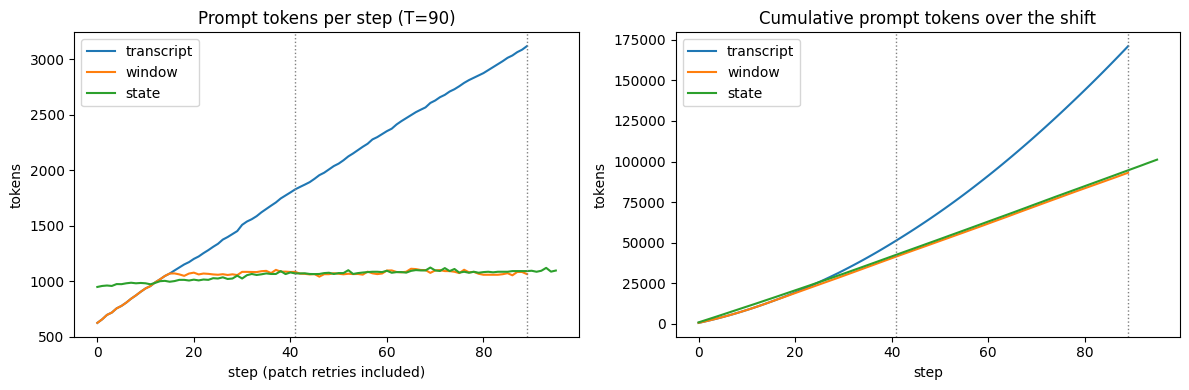

dotted lines: the two WRITE triggers

   T harness      first prompt  last prompt  max prompt  shift tokens
  30 transcript            623        1,543       1,543        33,225
  30 window                623        1,081       1,081        28,946
  30 state                 947        1,086       1,109        35,144
  90 transcript            623        3,118       3,118       171,892
  90 window                623        1,063       1,111        94,062
  90 state                 947        1,095       1,122       107,223


In [ ]:
import matplotlib.pyplot as plt


def track_rows(harness, T, seed):
    return [u for u in USAGE if u["label"] == f"track[{harness}|T={T}|s={seed}]"]


T_MAX, S0 = max(HORIZONS), SEEDS[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for h in HARNESSES:
    per_call = [u["prompt_tokens"] for u in track_rows(h, T_MAX, S0)]
    if per_call:
        ax1.plot(per_call, label=h)
        ax2.plot([sum(per_call[:i + 1]) for i in range(len(per_call))], label=h)
for i, e in enumerate(make_shift(T_MAX, S0)):
    if e.kind == "write":
        for ax in (ax1, ax2):
            ax.axvline(i, color="grey", ls=":", lw=1)
ax1.set(title=f"Prompt tokens per step (T={T_MAX})", xlabel="step (patch retries included)", ylabel="tokens")
ax2.set(title="Cumulative prompt tokens over the shift", xlabel="step", ylabel="tokens")
ax1.legend(); ax2.legend(); plt.tight_layout(); plt.show()
print("dotted lines: the two WRITE triggers\n")

print(f"{'T':>4} {'harness':<12}{'first prompt':>13}{'last prompt':>13}{'max prompt':>12}{'shift tokens':>14}")
for r in RUNS:
    rows = track_rows(r["harness"], r["T"], r["seed"])
    p = [u["prompt_tokens"] for u in rows]
    total = sum(u["prompt_tokens"] + u["completion_tokens"] for u in rows)
    print(f"{r['T']:>4} {r['harness']:<12}{p[0]:>13,}{p[-1]:>13,}{max(p):>12,}{total:>14,}")

## 6. Benefit 2: what the writer is handed

This is the benefit chapter 3 cannot provide, and it can be measured **before
any writer runs**, so it does not depend on how good the writer model is. For each
captured moment, the table counts two things in what the writer would receive:

- **traps**: each X is a decision the writer has to get right, at write time,
  inside the same generation that writes the prose.
- **facts**: the required facts that are present. An input can be free of traps
  simply because it has forgotten everything, which is what the window does at
  long horizons.

A clean input needs both: no X, and a full facts column.

The last column is a fact only the state harness can supply. Once the incident
timeline is structured, the harness can compute the duration itself. The incident
skill asks for it ("for how long"), and the identity forbids stating any number
that is not in the input. A writer holding only a transcript is caught between
those two rules.

In [ ]:
TRAP_MARKERS = {                       # must NOT reach a correct deliverable
    "dark mode":    r"dark mode",
    "40 %":         r"\b40 percent",
    "14:31":        r"14:31",
    "retries":      r"\bretries\b",
    "other branch": r"maintenance/|targets 2\.5\.0",
    "vendor":       r"\bvendor\b",
    "Globex":       r"globex",
}
RECORDED = ["14:02", "14:20", "14:36", "15:07"]
REQUIRED = {                           # MUST be available to write a correct deliverable
    "release-notes":   {"twice as fast": r"twice", "quote escaping": r"quot", "35 %": r"\b35 percent",
                        "job id": r"job id"},
    "incident-report": {t: re.escape(t) for t in RECORDED},
}


def _duration(timeline: Dict[str, str]) -> Optional[int]:
    keys = sorted(timeline)
    if len(keys) < 2:
        return None
    (h1, m1), (h2, m2) = (map(int, keys[0].split(":")), map(int, keys[-1].split(":")))
    return (h2 * 60 + m2) - (h1 * 60 + m1)


def writer_input(cap: Dict, skill: str) -> Tuple[Dict, str]:
    """(harness-owned facts for the surface, the user message): chapter 3 §5's tool result."""
    if cap["state"] is None:
        log = "\n".join(f"- {e}" for e in cap["log"])
        return dict(HARNESS_FACTS), f"Event log, oldest first:\n{log}\n\nTask: {cap['task']}"
    st = cap["state"]
    if skill == "release-notes":
        r = st.get("release", {})
        facts = {k: r[k] for k in ("version", "breaking") if r.get(k) is not None}
        body = "\n".join(f"- {c}" for _, c in sorted(r.get("changes", {}).items()))
        return facts, f"Release {r.get('version', '(version not recorded)')} of the Acme data platform.\n{body}"
    inc = st.get("incident", {})
    facts = {k: inc[k] for k in ("id", "status") if inc.get(k) is not None}
    if _duration(inc.get("timeline", {})) is not None:
        facts["duration_minutes"] = _duration(inc["timeline"])      # derived by the harness from Σ
    body = "\n".join(f"- {t} UTC — {e}" for t, e in sorted(inc.get("timeline", {}).items()))
    return facts, f"Incident {inc.get('id', '(id not recorded)')}. Recorded events, UTC, oldest first:\n{body}"


def exposure(cap, skill):
    facts, user = writer_input(cap, skill)
    text = (user + " " + json.dumps(facts)).lower()
    traps = {n: bool(re.search(rx, text)) for n, rx in TRAP_MARKERS.items()}
    have = sum(bool(re.search(rx, text)) for rx in REQUIRED[skill].values())
    return traps, have, ntok(user), facts


EXPOSURE: Dict[Tuple[str, int, int, str], Dict] = {}
for r in RUNS:
    for cap in r["captures"]:
        if cap["routed"] in WRITER_AXES:
            traps, have, tok, facts = exposure(cap, cap["routed"])
            EXPOSURE[(r["harness"], r["T"], r["seed"], cap["routed"])] = {
                "traps": traps, "have": have, "tok": tok, "derived": "duration_minutes" in facts}

for T in HORIZONS:
    print(f"\nT={T}, seed={SEEDS[0]}   (X = trap present in the writer's input)")
    print(f"   {'deliverable':<17}{'harness':<12}" + "".join(f"{n:>13}" for n in TRAP_MARKERS)
          + f"{'facts':>8}{'input tok':>11}  derived")
    for skill in ("incident-report", "release-notes"):
        for h in HARNESSES:
            e = EXPOSURE.get((h, T, SEEDS[0], skill))
            if e is None:
                print(f"   {skill:<17}{h:<12}  (no capture: the harness did not WRITE, or misrouted)")
                continue
            print(f"   {skill:<17}{h:<12}" + "".join(f"{'X' if e['traps'][n] else '.':>13}" for n in TRAP_MARKERS)
                  + f"{str(e['have']) + '/' + str(len(REQUIRED[skill])):>8}{e['tok']:>11}  "
                  + ("duration" if e["derived"] else "-"))


T=30, seed=0   (X = trap present in the writer's input)
   deliverable      harness         dark mode         40 %        14:31      retries other branch       vendor       Globex   facts  input tok  derived
   incident-report  transcript              X            X            X            .            X            X            X     4/4        347  -
   incident-report  window                  X            X            X            .            X            X            X     4/4        347  -
   incident-report  state                   .            .            .            .            .            .            .     4/4         69  duration
   release-notes    transcript              X            X            X            X            X            X            X     4/4        680  -
   release-notes    window                  X            .            .            X            X            .            .     2/4        358  -
   release-notes    state                   .         

In [ ]:
# The same moment, side by side: what the chapter-3 writer is handed, and what it is handed with Σ.
T_MAX, S0 = max(HORIZONS), SEEDS[0]
for h in ("transcript", "state"):
    r = run_of(h, T_MAX, S0)
    cap = next((c for c in (r["captures"] if r else []) if c["routed"] == "release-notes"), None)
    if cap is None:
        continue
    facts, user = writer_input(cap, "release-notes")
    lines = user.splitlines()
    print(f"--- release-notes input, {h} harness, T={T_MAX}: {len(lines)} lines, {ntok(user)} tokens, facts={facts}")
    shown = lines if len(lines) <= 14 else lines[:6] + [f"   ... {len(lines) - 12} more lines ..."] + lines[-6:]
    print(textwrap.indent("\n".join(shown), "   "), "\n")

--- release-notes input, transcript harness, T=90: 34 lines, 660 tokens, facts={'release_branch': 'release/2.4.0'}
   Event log, oldest first:
   - CI: build #6121 on main passed in 19m31s.
   - Merge queue: PR-530 merged into main (targets 2.5.0) — the scheduler accepts cron expressions.
   - Merge queue: PR-412 merged into release/2.4.0 — the CSV exporter was rewritten; exports run about twice as fast.
   - Chat (#support): ticket volume is normal today.
   - Merge queue: PR-415 merged into release/2.4.0 — peak memory during export reduced by roughly 40 percent.
      ... 22 more lines ...
   - Support: Globex says the outage broke their nightly load.
   - CI: build #6469 on main passed in 12m45s.
   - CI: build #8484 on main passed in 13m52s.
   - Merge queue: PR-420 merged into release/2.4.0 — the /v1/export endpoint now returns 202 with a job id instead of the file; callers must poll /v1/export/{id}.

   Task: Merge queue: PR-420 merged into release/2.4.0 — the /v1/export endpoint

## 7. Benefit 3: the deliverables

This is chapter 3's writing path, unchanged: route, `load_for_task` (with the
boundary check), `compile_surface` with the task's axes, and one typed call to the
same writer model at temperature 0. Only the input differs.

The graders are plain functions, and each one names a trap or a rule. A
deliverable scores 0 if its harness never wrote at the trigger, or if the router
picked the wrong skill. That failure belongs to the harness, and the notes say so.

In [ ]:
class IncidentReport(BaseModel):
    summary: str = Field(description="Two sentences.")
    timeline: List[str] = Field(description="One line per recorded event, each starting with its UTC time, oldest first.")


WHOLE_SCHEMA = {"release-notes": ReleaseNotes, "incident-report": IncidentReport}


def write(cap: Dict, skill: str, label: str):
    """Chapter 3's writer: compile the surface for this task, one typed call."""
    facts, user = writer_input(cap, skill)
    surface_ = compile_surface(artifacts=load_for_task([skill, "plainspoken"]),
                               axes=WRITER_AXES[skill], facts=facts)
    out = typed_call(model=WRITER, response_model=WHOLE_SCHEMA[skill], temperature=0.0, label=label,
                     messages=[{"role": "system", "content": surface_.text},
                               {"role": "user", "content": user}])
    return out, surface_.manifest["surface_digest"], user + " " + json.dumps(facts)


def grade_release(n: ReleaseNotes) -> Dict[str, bool]:
    text = n.summary + " " + " ".join(n.highlights)
    low = text.lower()
    return {
        "covers exporter speed":            bool(re.search(r"twice|two times|\b2x\b|2×", low)),
        "covers quote escaping":            "quot" in low,
        "covers export memory":             "memory" in low,
        "covers export retrieval (job)":    "job" in low,
        "current number (35, not 40)":      bool(re.search(r"\b35\b", low)) and not re.search(r"(?<!not )\b40\b", low),
        "no reverted change (dark mode)":   "dark mode" not in low,
        "no moved change (retries)":        not re.search(r"\bretr(y|ies)\b", low),
        "no other-branch change":           not re.search(r"time ?zone|cron|gzip|last-used", low),
        "no named customer":                "globex" not in low,
        "customer: no status code/path":    not re.search(r"\b202\b|/v1/", text),
        "contract: 3-6 bullets, <=25 words": 3 <= len(n.highlights) <= 6 and len(n.summary.split()) <= 25,
        "no '!' or superlative":            "!" not in text and not re.search(r"\b(best|fastest|most powerful)\b", low),
    }


def grade_incident(r: IncidentReport) -> Dict[str, bool]:
    times = [m.group(1) for line in r.timeline if (m := re.match(r"\s*(\d{2}:\d{2})", line))]
    text = r.summary + " " + " ".join(r.timeline)
    low = text.lower()
    return {
        "all recorded times present":       all(t in times for t in RECORDED),
        "superseded 14:31 absent":          "14:31" not in text,
        "only recorded events":             set(times) <= set(RECORDED),
        "every line starts with a time":    bool(r.timeline) and len(times) == len(r.timeline),
        "oldest first":                     times == sorted(times),
        "duration stated (65 minutes)":     bool(re.search(r"\b65[ -]minute", low)),
        "no cause speculation / vendor":    not re.search(r"vendor|load balancer", low),
        "no named customer":                "globex" not in low,
        "no apology opener":                not re.match(r"\s*(we('| a)re sorry|we apologi|sorry|apolog)", r.summary.lower()),
        "summary: two sentences":           len(re.findall(r"[.!?](?=\s|$)", r.summary.strip())) == 2,
    }


GRADERS = {"release-notes": grade_release, "incident-report": grade_incident}


def deliver(run: Dict, skill: str) -> Dict:
    due = next(i for i, e in enumerate(make_shift(run["T"], run["seed"])) if e.expect == skill)
    cap = next((c for c in run["captures"] if c["t"] == due), None)
    row = {"harness": run["harness"], "T": run["T"], "seed": run["seed"], "skill": skill,
           "output": None, "checks": None, "score": 0.0, "note": None, "input": None,
           "surface": None, "state_digest": None}
    if cap is None:
        row["note"] = f"no WRITE at t={due}"
    elif cap["routed"] != skill:
        row["note"] = f"routed to {cap['routed']}"
    else:
        try:
            out, digest, used = write(cap, skill, f"write[{run['tag']}|{skill}]")
            checks = GRADERS[skill](out)
            row.update(output=out, checks=checks, score=sum(checks.values()) / len(checks), input=used,
                       surface=digest, state_digest=cap["state_digest"])
        except Exception as exc:                              # noqa: BLE001
            row["note"] = f"{type(exc).__name__}: {exc}"[:200]
    return row


with cf.ThreadPoolExecutor(MAX_WORKERS) as pool:
    DELIVERED = list(pool.map(lambda j: deliver(*j), [(r, skill) for r in RUNS for skill in GRADERS]))

for d in DELIVERED:
    if d["note"]:
        print(f"   {d['harness']:<11} T={d['T']:<4} {d['skill']:<17} scored 0: {d['note']}")
print(f"{len(DELIVERED)} deliverables written and graded")

12 deliverables written and graded


In [ ]:
# Which trap each harness fell into. '.' pass, 'X' fail, '-' not written.
for skill in ("incident-report", "release-notes"):
    rows = [d for d in DELIVERED if d["skill"] == skill and d["seed"] == SEEDS[0]]
    names = next((list(d["checks"]) for d in rows if d["checks"]), [])
    cols = [(h, T) for T in HORIZONS for h in HARNESSES]
    print(f"\n{skill}")
    print(f"   {'check':<36}" + "".join(f"{h[:5] + '@' + str(T):>11}" for h, T in cols))
    for name in names:
        cells = []
        for h, T in cols:
            d = next((d for d in rows if d["harness"] == h and d["T"] == T), None)
            cells.append("-" if d is None or d["checks"] is None else ("." if d["checks"][name] else "X"))
        print(f"   {name:<36}" + "".join(f"{c:>11}" for c in cells))
    print(f"   {'score':<36}" + "".join(
        f"{next((d['score'] for d in rows if d['harness'] == h and d['T'] == T), 0):>11.2f}" for h, T in cols))

T_MAX, S0 = max(HORIZONS), SEEDS[0]
for h in ("transcript", "state"):
    d = next((d for d in DELIVERED if d["harness"] == h and d["T"] == T_MAX and d["seed"] == S0
              and d["skill"] == "release-notes" and d["output"]), None)
    if d:
        print(f"\n--- release notes, {h} harness, T={T_MAX}")
        print(f"  summary  : {d['output'].summary}")
        for line in d["output"].highlights:
            print(f"  highlight: {line}")


incident-report
   check                                  trans@30   windo@30   state@30   trans@90   windo@90   state@90
   all recorded times present                    .          .          .          .          X          .
   superseded 14:31 absent                       .          .          .          .          X          .
   only recorded events                          .          .          .          .          .          .
   every line starts with a time                 .          .          .          .          .          .
   oldest first                                  .          .          .          .          .          .
   duration stated (65 minutes)                  .          .          .          .          X          .
   no cause speculation / vendor                 .          .          .          .          .          .
   no named customer                             .          .          .          .          .          .
   no apology opener         

## 8. Benefit 4: tests the harness can now run

Chapter 3's section 8 split skill testing in two: tests on the **surface**, which
need no model, and tests on the **output**, which need generated text. With Σ in
place, a third kind becomes possible: **tests on the output against the facts it
was given**.

- **Provenance.** Every number and time in a deliverable must appear in the
  writer's input. This is the identity's first refusal, turned into a check that
  runs every time. Against a transcript it is nearly toothless: the stale `40` and
  `14:31` are *in* the log, so a deliverable that repeats them passes. Against Σ it
  catches exactly the values that were superseded, because Σ no longer contains
  them.

  A good writer may never actually ship a stale value, so waiting for one to show
  up would prove nothing. The cell therefore runs a **mutation test**, in the same
  spirit as chapter 3's SME edit. It plants the stale value (the 40, or the 14:31
  line) into each real deliverable, and asks whether that harness's provenance test
  catches it. The answer is deterministic, and it does not depend on the model.
- **A trace you can audit.** Chapter 3's section 9 put the surface digest in the
  trace, which records *which rules* a run used. The state digest records *which
  facts*. When a deliverable is wrong three weeks later, the pair tells you whether
  a rule or a fact caused it, and Σ is small enough to read.

In [ ]:
NUM = r"\d+(?:[.:]\d+)*"
STALE = {"release-notes": r"(?<!not )\b40\b", "incident-report": r"14:31"}


def provenance(output, input_text) -> List[str]:
    text = " ".join(v if isinstance(v, str) else " ".join(v) for v in output.model_dump().values())
    return sorted(set(re.findall(NUM, text)) - set(re.findall(NUM, input_text)))


def plant_stale(d):
    """The mutation: the superseded value, written into an otherwise real deliverable."""
    o = d["output"]
    if d["skill"] == "release-notes":
        return ReleaseNotes(summary=o.summary, highlights=o.highlights + ["Use about 40 percent less memory on big exports"])
    return IncidentReport(summary=o.summary, timeline=o.timeline + ["14:31 UTC — ingest API recovered in eu-west"])


MUTATION: Dict[Tuple[str, int, int, str], bool] = {}
print(f"{'T':>4} {'harness':<12}{'deliverable':<17}{'real output':>16}{'planted stale value':>22}   trace")
for d in DELIVERED:
    if d["output"] is None:
        continue
    real = provenance(d["output"], d["input"])
    caught = bool({"40", "14:31"} & set(provenance(plant_stale(d), d["input"])))
    MUTATION[(d["harness"], d["T"], d["seed"], d["skill"])] = caught
    trace = f"surface={d['surface']}" + (f" state={d['state_digest']}" if d["state_digest"] else " state=—")
    print(f"{d['T']:>4} {d['harness']:<12}{d['skill']:<17}{('flags ' + str(real)) if real else 'passes':>16}"
          f"{'CAUGHT' if caught else 'missed':>22}   {trace}")

print("\n'missed' means the stale value is in that harness's input, so the test cannot tell it\n"
      "from a real fact. That is the transcript harness's normal case, by construction.")

st = run_of("state", max(HORIZONS), SEEDS[0])
if st:
    print(f"\nthe facts behind every state-harness deliverable at T={max(HORIZONS)} "
          f"({len(json.dumps(st['final_state']))} chars, final Σ):")
    print(textwrap.indent(json.dumps(st["final_state"], indent=2), "   "))

   T harness     deliverable           real output   planted stale value   trace
  30 transcript  release-notes              passes                missed   surface=69b4754f6d1f state=—
  30 transcript  incident-report      flags ['65']                missed   surface=320f0853b22a state=—
  30 window      release-notes              passes                missed   surface=69b4754f6d1f state=—
  30 window      incident-report      flags ['65']                missed   surface=320f0853b22a state=—
  30 state       release-notes              passes                CAUGHT   surface=61368dc1fa99 state=6f94ff8d3310
  30 state       incident-report            passes                CAUGHT   surface=577e98a9e32c state=c3f3aef45338
  90 transcript  release-notes              passes                missed   surface=69b4754f6d1f state=—
  90 transcript  incident-report      flags ['65']                missed   surface=320f0853b22a state=—
  90 window      release-notes              passes               

## 9. The scorecard

The four benefits, per horizon, on one page. The two headline columns are
`transcript` (chapter 3's harness run over a stream) and `state` (the same harness
with SKILL.state). `window` is the control.


T=30
                                           transcript          window           state
   shift tokens (tracker)                      33,225          28,946          35,144
   max prompt tokens                            1,543           1,081           1,109
   traps in writer input (of 14)                13.00            9.00            0.00
   required facts present (of 8)                 8.00            6.00            8.00
   writer input tokens                          1,027             705             147
   deliverable score (mean)                      0.96            0.92            0.96
   stale values in deliverables                  0.00            0.00            0.00
   planted stale values caught                   0.00            0.00            2.00
   fact digest in trace                            no              no             yes

T=90
                                           transcript          window           state
   shift tokens (tracker)                 

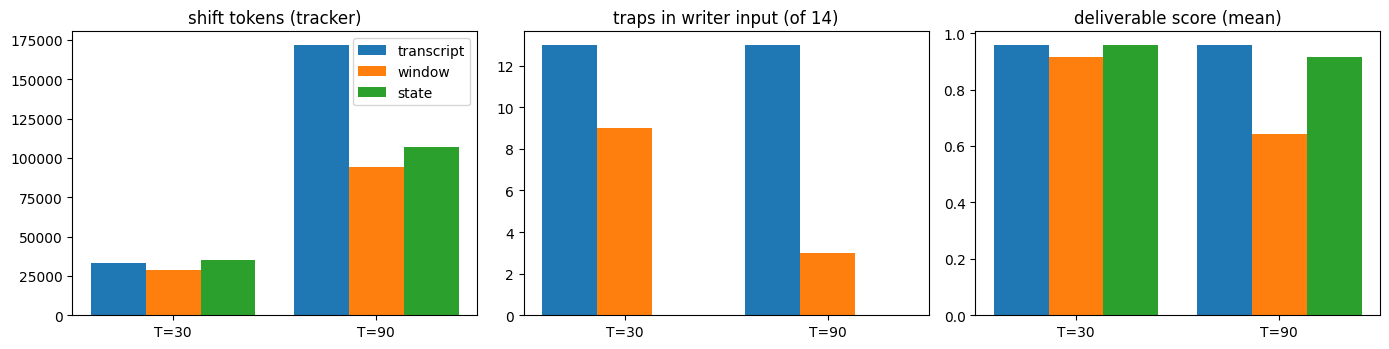

In [ ]:
def scorecard(T):
    card = {}
    for h in HARNESSES:
        rows = [u for s in SEEDS for u in USAGE if u["label"] == f"track[{h}|T={T}|s={s}]"]
        exp = [e for (hh, TT, s, _), e in EXPOSURE.items() if hh == h and TT == T]
        dl = [d for d in DELIVERED if d["harness"] == h and d["T"] == T]
        n = len(SEEDS)
        card[h] = {
            "shift tokens (tracker)":        sum(u["prompt_tokens"] + u["completion_tokens"] for u in rows) / n,
            "max prompt tokens":             max((u["prompt_tokens"] for u in rows), default=0),
            "traps in writer input (of 14)": sum(sum(e["traps"].values()) for e in exp) / n,
            "required facts present (of 8)": sum(e["have"] for e in exp) / n,
            "writer input tokens":           sum(e["tok"] for e in exp) / n,
            "deliverable score (mean)":      sum(d["score"] for d in dl) / max(len(dl), 1),
            "stale values in deliverables":  sum(bool(d["output"] and re.search(STALE[d["skill"]],
                                                 " ".join(str(v) for v in d["output"].model_dump().values())))
                                                 for d in dl) / n,
            "planted stale values caught":   sum(v for (hh, TT, s, _), v in MUTATION.items() if hh == h and TT == T) / n,
            "fact digest in trace":          "yes" if h == "state" else "no",
        }
    return card


for T in HORIZONS:
    card = scorecard(T)
    print(f"\nT={T}")
    print(f"   {'':34}" + "".join(f"{h:>16}" for h in HARNESSES))
    for metric in card["state"]:
        vals = [card[h][metric] for h in HARNESSES]
        fmt = [f"{v:>16,.0f}" if isinstance(v, (int, float)) and v >= 100 else
               f"{v:>16.2f}" if isinstance(v, float) else f"{str(v)[:15]:>16}" for v in vals]
        print(f"   {metric:<34}" + "".join(fmt))

# The same, as a picture across horizons.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, metric in zip(axes, ["shift tokens (tracker)", "traps in writer input (of 14)", "deliverable score (mean)"]):
    for i, h in enumerate(HARNESSES):
        ax.bar([x + i * 0.27 for x in range(len(HORIZONS))], [scorecard(T)[h][metric] for T in HORIZONS],
               width=0.27, label=h)
    ax.set_xticks([x + 0.27 for x in range(len(HORIZONS))], [f"T={T}" for T in HORIZONS])
    ax.set_title(metric)
axes[0].legend(); plt.tight_layout(); plt.show()

**Reading your own run.** Read the scorecard from top to bottom. The earlier rows
depend least on the models, and the later rows depend most.

- **Shift tokens and max prompt** separate on any model. The gap is small at a short
  horizon, because the state harness's fixed instructions are larger. It widens with
  `T`. Add 180 to `HORIZONS` to see the transcript curve bend upwards.
- **Traps and facts in the writer's input** are measured before any writer runs.
  They show the state boundary's contribution directly. For the transcript, every
  trap is in the input by construction. For the window, the traps and the facts
  scroll out of view together. For the state harness, the traps are gone and the
  facts are still there, provided the tracker recorded them.
- **Deliverable score** is where a strong writer can narrow the gap. A good model
  handed a 90-event log will often resolve most traps by itself. If your run shows
  a tie here, the supported claim is: *the same deliverables, from a fraction of the
  tokens, from an input you can read and audit, with a provenance test that works.*
  That is still the argument for state. It is simply a different argument from
  "better text".
- **Planted stale values caught** is the row chapter 3 has no answer for. When
  the transcript harness ships a stale 40, nothing in the harness can notice it,
  because the 40 is in the input.

**What would count against it.** If the state harness misses facts that the
transcript harness got right, check the final Σ in section 8. That is the
sufficient-statistic caveat in section 10 happening in front of you: a fact the
tracker did not record on the one step it was visible. One seed per horizon is a
demonstration, not a statistic. Raise `SEEDS` before you claim more.

## 10. When explicit state does not help

Dropping history is safe only if Σ is a *sufficient statistic*: it has to hold
everything the next steps depend on. That assumption has costs, and an honest
harness names them:

- **The schema must anticipate the relevant state.** A fact with no field has
  nowhere to go. The desk schema has no field for "customers who complained".
  That is correct here, because the identity forbids naming them. For a different
  deliverable, it would be a silent loss.
- **A fact not captured when it is observed is lost.** The observation is gone on
  the next step, and no later step can recover it.
- **Historical and audit tasks need the trajectory.** "Why did the agent write X?"
  is answered by the trace, not by Σ. The runtime hands each step's reasoning to
  `on_step` for exactly this reason, and never feeds it back.
- **"O(1) prompt" assumes bounded state.** A Σ that accumulates every item ever
  seen is a transcript with braces. `max_state_chars` enforces the bound, and the
  schema should say what gets deleted.
- **Structure does not make updates correct.** Section 3's last test showed a
  well-formed, wrong patch passing validation. The runtime guarantees shape and
  invariants, not truth.

This chapter also leaves out several things. There is one domain, one tracker
model and one writer model, and the graders catch only the failure modes they
name. It runs a single agent; several agents writing to one Σ need conflict rules
in the merge operator that this setup never exercises.

## 11. What this pass cost

In [ ]:
@lru_cache(maxsize=1)
def pricing() -> Dict[str, Tuple[float, float]]:
    req = urllib.request.Request(f"{BASE_URL}/models",
                                 headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"})
    data = json.load(urllib.request.urlopen(req, timeout=60))["data"]
    return {m["id"]: (float(m["pricing"]["prompt"]), float(m["pricing"]["completion"])) for m in data}


def cost_of(u) -> float:
    p_in, p_out = pricing().get(u["model"], (0.0, 0.0))
    return u["prompt_tokens"] * p_in + u["completion_tokens"] * p_out


agg: Dict[Tuple[str, str], Dict[str, float]] = {}
for u in USAGE:
    role, _, rest = u["label"].partition("[")
    a = agg.setdefault((role, rest.split("|")[0]), {"n": 0, "in": 0, "out": 0, "usd": 0.0})
    a["n"] += 1; a["in"] += u["prompt_tokens"]; a["out"] += u["completion_tokens"]; a["usd"] += cost_of(u)

print(f"{'role':<8}{'harness':<14}{'calls':>7}{'tok in':>12}{'tok out':>10}{'USD':>10}")
for (role, who), a in sorted(agg.items()):
    print(f"{role:<8}{who:<14}{a['n']:>7}{a['in']:>12,}{a['out']:>10,}{a['usd']:>10.5f}")
print(f"{'total':<22}{sum(a['n'] for a in agg.values()):>7}{sum(a['in'] for a in agg.values()):>12,}"
      f"{sum(a['out'] for a in agg.values()):>10,}{sum(a['usd'] for a in agg.values()):>10.5f}")
print("\nPriced from the published per-token rates against measured tokens; treat it as the\n"
      "cost of the work, not a reconciliation of an account.")

role    harness         calls      tok in   tok out       USD
route   state               5       1,036       184   0.00161
route   transcript          6       1,243       215   0.00190
route   window              5       1,036       183   0.00160
track   state             127     133,904     8,463   0.13851
track   transcript        120     203,971     1,146   0.15814
track   window            120     121,698     1,310   0.09717
write   state               4       3,562       866   0.00175
write   transcript          4       6,772       489   0.00194
write   window              4       4,609       927   0.00203
total                     395     477,831    13,783   0.40465

Priced from the published per-token rates against measured tokens; treat it as the
cost of the work, not a reconciliation of an account.


## 12. What chapter 3 plus explicit state gives you

| Chapter 3 built | Chapter 4 extends it to | What it now answers |
|---|---|---|
| artifacts as typed, hashed, versioned records | the state schema as an artifact | "What facts can this task hold?" |
| a boundary check on section ownership | a validation check on every patch | "Can this update corrupt what we know?" |
| a compiled surface: only the rules that apply | a compiled Σ: only the facts that are true | "What is the writer being told is true?" |
| surface tests and output tests | provenance tests against the input | "Did the output invent or keep a stale fact?" |
| the surface digest in the trace | the state digest next to it | "Was it a rule or a fact?" |

### Adapting this to your own agent

1. **Find where facts get resolved.** If the answer is "the writer, at write time,
   from the log", you have the transcript harness from this chapter, whatever it is
   called in your code.
2. **Author the state schema like a skill**: once per domain, versioned and
   reviewed. Say what gets deleted, not only what gets added.
3. **Validate every patch in code before committing it.** Refuse, keep Σ as it was,
   and retry with the error. Cap the size.
4. **Hand the writer Σ, never the log.** Compute what the harness can compute, such
   as durations, counts and flags, and supply it as facts.
5. **Add the provenance test.** It costs nothing to run, and it only works once the
   input holds current facts.
6. **Keep the trace, and never feed it back.** Audits need it; the next step does
   not.